# 10 · Choosing the supervised model

**The question.** Which supervised model should WildGuard use, trained how? This is DESIGN_QUESTIONS Part B, B2–B5. The current pipeline chose XGBoost in advance and compared two other models afterwards; here every candidate is tuned and compared under one protocol, decided on 31 October 2026 before any result was seen.

**The protocol (DESIGN_QUESTIONS B1–B5):**
- **Data.** Animals with a class (ALIGNING §2.2); the features both datasets record (`SHARED_FEATURES`), plus any adopted by S2.2 (notebook 09).
- **Year roles (B1).** Tuning by time-ordered cross-validation inside the training years: fold 1 trains on 2000–2006 and validates on 2007–2008; fold 2 trains on 2000–2008 and validates on 2009–2010. Peer norms are learned on each fold's training years, so they never see its validation years. Models are fitted on 20% of the training shipments, whole shipments kept together; validation uses all listed line items of the validation years. 2011 decides between the candidates. 2012–2014 are not used.
- **Candidates (B2).** Logistic regression, naive Bayes, decision tree, random forest, AdaBoost, XGBoost. (Out, with reasons in B2: linear SVM, MLP, kernel SVM, k-nearest neighbours.)
- **Preparation (B3).** One-hot categories and z-scored numerics for logistic regression; categories and ten quantile bins of each numeric for naive Bayes; integer codes for the scikit-learn trees; native categories for XGBoost. Class-imbalance handling is part of each candidate's search: none, class weights, undersampling the cleared line items, SMOTE-NC, and for the ensembles balanced random forest and RUSBoost.
- **Tuning (B4).** Five designed configurations per candidate, each scored by its mean PR-AUC over the two folds on listed line items. Configurations 1–4 compare the class-imbalance options at standard settings; configuration 5 changes the candidate's main setting, using the best of 1–4. For logistic regression the fifth swaps L-BFGS for stochastic gradient descent, so the optimisers are compared like for like. XGBoost stops early on the fold's validation part. (Five configurations replaced a random search of 20 to keep the search to about an hour; a candidate could lose for want of tuning.)
- **Choice (B5).** Each candidate's best configuration is refitted on all of 2000–2010 and scored on 2011. The best PR-AUC on listed 2011 line items wins; a candidate whose 95% paired-bootstrap interval against the best includes zero counts as tied, and ties go to the simpler model in the order logistic regression, naive Bayes, decision tree, random forest, AdaBoost, XGBoost.

The search and refits take about an hour, so their results are saved in `DATA/processed/experiments/` and read back when the notebook is rebuilt.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

import eda_setup as E
import experiment_setup as X_
import model_selection as M
from wildguard import config
from wildguard.features import SHARED_FEATURES

E.style()
OUT = config.PROCESSED_DIR / "experiments"
OUT.mkdir(exist_ok=True)
CONSIGNMENT = ["cons_sources"]          # adopted by notebook 09 (S2.2)
FEATS = SHARED_FEATURES + CONSIGNMENT
df = X_.load_lemis()
# number of distinct sources in each line item's shipment (all its line items, as in notebook 09)
cons = df.groupby("shipment_id")["source"].nunique().rename("cons_sources")
df = df[df["animal"]].join(cons, on="shipment_id").reset_index(drop=True)
print(f"{len(df):,} line items; features: {len(FEATS)}")

5,107,119 line items; features: 22


## 1. The search

In [2]:
# run_model_search.py runs this ahead of the notebook; the call reads its saved results
t0 = time.time()
search = M.search(df, FEATS, M.SIMPLICITY, cache_dir=OUT,
                  log=lambda m: print(f"[{time.time() - t0:5.0f}s] {m}", flush=True))
best = search.loc[search.groupby("candidate")["pr_auc"].idxmax()].set_index("candidate").loc[M.SIMPLICITY]
best[["config", "imbalance", "pr_auc_fold1", "pr_auc_fold2", "pr_auc", "seconds"]].style.format(
    {"pr_auc_fold1": "{:.3f}", "pr_auc_fold2": "{:.3f}", "pr_auc": "{:.3f}", "seconds": "{:.0f}"})

[    0s] read from cache: ['logistic_regression', 'naive_bayes', 'decision_tree', 'random_forest', 'adaboost', 'xgboost']


,config,imbalance,pr_auc_fold1,pr_auc_fold2,pr_auc,seconds
candidate,,,,,,
logistic_regression,1,none,0.551,0.501,0.526,4
naive_bayes,5,smotenc,0.413,0.368,0.391,30
decision_tree,3,undersample,0.461,0.405,0.433,1
random_forest,1,none,0.591,0.521,0.556,27
adaboost,4,smotenc,0.508,0.440,0.474,216
xgboost,5,none,0.599,0.541,0.570,26


Every configuration tried, by candidate (each point is one configuration's mean PR-AUC over the two folds):

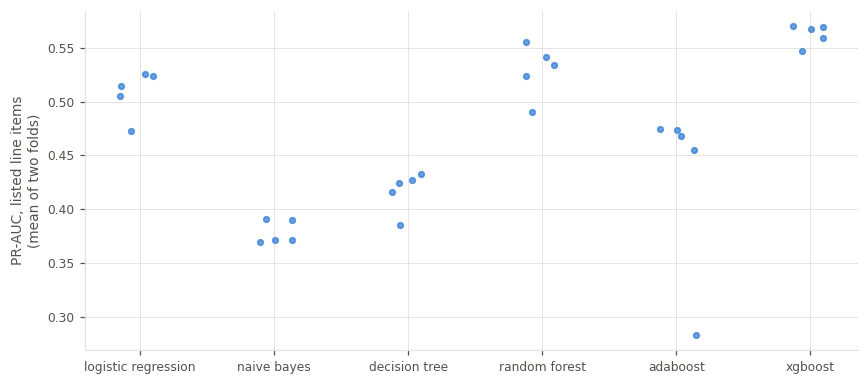

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, c in enumerate(M.SIMPLICITY):
    v = search.loc[search.candidate == c, "pr_auc"]
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)), v,
               s=14, color=E.LEMIS_C, alpha=0.7)
ax.set_xticks(range(len(M.SIMPLICITY)), [c.replace("_", " ") for c in M.SIMPLICITY])
ax.set_ylabel("PR-AUC, listed line items\n(mean of two folds)")
plt.tight_layout()

How each way of handling the class imbalance did, by candidate (configurations 1–4, at standard settings; configuration 5 adds a second value for the winning option):

In [4]:
search.pivot_table(index="candidate", columns="imbalance", values="pr_auc", aggfunc="max").loc[
    M.SIMPLICITY].style.format("{:.3f}", na_rep="—")

imbalance,balanced_rf,class_weight,none,rusboost,smotenc,undersample
candidate,,,,,,
logistic_regression,—,0.473,0.526,—,0.505,0.515
naive_bayes,—,0.371,0.371,—,0.391,0.370
decision_tree,—,0.385,0.425,—,0.416,0.433
random_forest,0.534,0.490,0.556,—,0.542,—
adaboost,—,0.473,0.455,0.283,0.474,—
xgboost,—,0.559,0.570,—,0.547,0.568


## 2. Each candidate's best configuration, refitted on 2000–2010 and scored on 2011

In [5]:
path = OUT / "scores_2011.parquet"
ev = df[df["year"] == 2011].reset_index(drop=True)
if path.exists():
    S = pd.read_parquet(path)
else:
    S = ev[["shipment_id", "label", "sp_listed", "purpose"]].copy()
    for c in M.SIMPLICITY:
        row = best.loc[c]
        t = time.time()
        cfg = M.config_from_row({**row.to_dict(), "candidate": c})
        rounds = None if pd.isna(row["best_rounds"]) else int(row["best_rounds"])
        S[c] = M.refit_and_score(df, FEATS, c, cfg, rounds)
        print(f"{c}: refitted and scored ({time.time() - t:.0f}s)", flush=True)
    S.to_parquet(path)
listed = S["sp_listed"].to_numpy()

## 3. The choice (B5)

In [6]:
ap = {c: average_precision_score(S.label[listed], S[c][listed]) for c in M.SIMPLICITY}
top = max(ap, key=ap.get)
cmp = X_.pr_auc_bootstrap(S.label.to_numpy()[listed], {c: S[c].to_numpy()[listed] for c in M.SIMPLICITY},
                          S.shipment_id.to_numpy()[listed], [(c, top) for c in M.SIMPLICITY if c != top])
cmp = cmp.set_index("a")[["pr_auc_a", "difference", "low_95", "high_95"]]
cmp["tied with the best"] = cmp["high_95"] >= 0
cmp.columns = ["PR-AUC (listed, 2011)", f"− {top}", "95% low", "95% high", "tied with the best"]
display(cmp.style.format({c: "{:.3f}" for c in cmp.columns[:4]}))
tied = [top] + cmp.index[cmp["tied with the best"]].tolist()
CHOICE = min(tied, key=M.SIMPLICITY.index)
print(f"Best on listed 2011 line items: {top} (PR-AUC {ap[top]:.3f}); tied: {tied}; "
      f"choice by the tie rule: {CHOICE}")

,"PR-AUC (listed, 2011)",− random_forest,95% low,95% high,tied with the best
a,,,,,
logistic_regression,0.498,-0.073,-0.085,-0.060,False
naive_bayes,0.377,-0.193,-0.217,-0.170,False
decision_tree,0.458,-0.113,-0.127,-0.098,False
adaboost,0.414,-0.156,-0.178,-0.137,False
xgboost,0.565,-0.005,-0.012,0.002,True


Best on listed 2011 line items: random_forest (PR-AUC 0.570); tied: ['random_forest', 'xgboost']; choice by the tie rule: random_forest


Alongside, not deciding (B4): every candidate on all 2011 line items, and the recall a 1% and a 5% review budget would reach on listed line items.

In [7]:
def recall_at(y, s, frac):
    k = max(1, int(round(len(s) * frac)))
    return y[np.argsort(-s, kind="stable")[:k]].sum() / y.sum()


pd.DataFrame({c: {"PR-AUC, listed": ap[c],
                  "PR-AUC, all": average_precision_score(S.label, S[c]),
                  "recall at 1%, listed": recall_at(S.label.to_numpy()[listed], S[c].to_numpy()[listed], 0.01),
                  "recall at 5%, listed": recall_at(S.label.to_numpy()[listed], S[c].to_numpy()[listed], 0.05)}
              for c in M.SIMPLICITY}).T.style.format("{:.3f}")

,"PR-AUC, listed","PR-AUC, all","recall at 1%, listed","recall at 5%, listed"
logistic_regression,0.498,0.604,0.341,0.576
naive_bayes,0.377,0.477,0.268,0.528
decision_tree,0.458,0.550,0.321,0.595
random_forest,0.570,0.658,0.386,0.632
adaboost,0.414,0.512,0.299,0.547
xgboost,0.565,0.660,0.376,0.634


## 4. How alike are the candidates' errors? (the first step of B6)

Ensembles gain most from members whose errors are weakly correlated (PRMLS Day 5). For each pair of candidates: the overlap of their top-1% sets on listed 2011 line items, and the rank correlation of their scores on enforcement cases.

In [8]:
k = int(round(listed.sum() * 0.01))
tops = {c: set(np.argsort(-S[c].to_numpy()[listed])[:k]) for c in M.SIMPLICITY}
overlap = pd.DataFrame({a: {b: len(tops[a] & tops[b]) / k for b in M.SIMPLICITY} for a in M.SIMPLICITY})
cases = S[listed & (S.label == 1)][M.SIMPLICITY].rank()
display(overlap.style.format("{:.0%}").set_caption("Overlap of top-1% sets"))
cases.corr(method="spearman").style.format("{:.2f}").set_caption("Rank correlation of scores on enforcement cases")

,logistic_regression,naive_bayes,decision_tree,random_forest,adaboost,xgboost
logistic_regression,100%,63%,67%,79%,73%,84%
naive_bayes,63%,100%,55%,61%,59%,60%
decision_tree,67%,55%,100%,75%,70%,72%
random_forest,79%,61%,75%,100%,70%,87%
adaboost,73%,59%,70%,70%,100%,67%
xgboost,84%,60%,72%,87%,67%,100%


,logistic_regression,naive_bayes,decision_tree,random_forest,adaboost,xgboost
logistic_regression,1.00,0.89,0.83,0.89,0.92,0.93
naive_bayes,0.89,1.00,0.81,0.84,0.87,0.86
decision_tree,0.83,0.81,1.00,0.89,0.88,0.89
random_forest,0.89,0.84,0.89,1.00,0.88,0.96
adaboost,0.92,0.87,0.88,0.88,1.00,0.90
xgboost,0.93,0.86,0.89,0.96,0.90,1.00


## Findings

| # | Finding |
|---|---|
| T1 | In the cross-validation (mean PR-AUC of two folds, listed line items): XGBoost 0.570, random forest 0.556, logistic regression 0.526, AdaBoost 0.474, decision tree 0.433, naive Bayes 0.391 |
| T2 | On 2011, listed line items: random forest 0.570 and XGBoost 0.565 are tied (difference −0.005, 95% interval −0.012 to +0.002); every other candidate is significantly worse (logistic regression −0.073, decision tree −0.113, AdaBoost −0.156, naive Bayes −0.193). The tie rule takes the simpler model: **random forest** |
| T3 | **Class imbalance.** For the strong candidates, no imbalance handling ranked best, and class weights lowered PR-AUC (logistic regression 0.526 → 0.473, random forest 0.556 → 0.490, XGBoost 0.570 → 0.559, decision tree 0.425 → 0.385). SMOTE-NC helped only the weak candidates (naive Bayes and AdaBoost, about +0.02), and RUSBoost did worst (0.283). PR-AUC judges the ranking, not a threshold: reweighting moves the decision boundary but does not improve the order of records, and adds variance. The current pipeline's class weight for XGBoost was slightly worse than none |
| T4 | **Optimiser.** For logistic regression, stochastic gradient descent and L-BFGS did the same (0.524 against 0.526) |
| T5 | **Correlated errors.** The strong candidates agree on most of their top 1% (random forest and XGBoost 87%, logistic regression and XGBoost 84%), and their scores on enforcement cases are highly rank-correlated (0.81–0.96). An ensemble of them can gain little (B6 tests it) |
| T6 | **Not covered by the rule:** the two tied models differ in what deploying them takes. Random forest: 96 MB saved (4.27 million tree nodes; roughly 340 MB in memory), and its plain-language reasons need an extra package. XGBoost: 1 MB, with exact per-feature contributions built in (report §4.6). The hosted app already uses about 560–650 MB |

**Decision (B5, 31 October 2026): XGBoost**, configuration 5: no class-imbalance handling, depth 6, learning rate 0.05, minimum child weight 20, row and column subsampling 0.8, with the number of rounds found by early stopping in the folds.

The rule as written chose random forest, the simpler method of the two tied models. After seeing the tie, the choice was made on deployment cost instead (T6): random forest would add roughly 340 MB to an app that already uses about 560–650 MB, and would need an extra package for its plain-language reasons, while XGBoost is 1 MB with exact contributions built in. The performance difference is not significant either way. The report states that the tie was broken after the result was seen, and why.